# 과제 3 — ACT chunk_size 비교 실험

**과제 내용**: 같은 데이터셋으로 `chunk_size`만 10, 50, 100으로 바꾼 ACT 정책 3개를 학습하고, 실제 로봇에서 각각 10회씩 평가해 chunk_size가 성공률·동작의 부드러움·반응성에 주는 영향을 분석한다. chunk_size=100 정책에는 temporal ensemble을 적용해 10회 더 평가하고 결과를 비교한다. 학습된 정책 3개는 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1, 2와 같은 저장소, assignments 폴더)에 `assignment_3.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 이번 과제는 **통제 실험**이다. 실험할 ACT 정책 3개는 `chunk_size`와 `n_action_steps`를 제외한 모든 설정(데이터셋, steps, batch_size, seed)이 같아야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 과제 2의 정책(기본값 chunk_size=100)을 chunk_size=100 조건으로 **재사용해도 된다.** 이 경우 나머지 두 정책은 과제 2와 같은 데이터셋·steps·batch_size·seed로 학습해야 한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

> 2026-11-14 작성. 세 ACT 모델 모두 100,000스텝 학습 및 Hub 업로드를 완료했다. 기본 조건 3개와 temporal ensemble 조건에서 각각 10회씩, 총 40회 평가를 저장했다.
> 작업은 팔로워 암 기준 좌측 큐브를 집어 우측에 내려놓는 것이다. 모든 평가의 성공 여부와 부드러움 점수는 실험자 관찰 기록을 사용했다.
> 반응성 테스트는 실험자의 추가 확인에 따라 조건별 3회 모두 새 물체 위치를 따라가지 못한 것으로 기록했다. 추론 지연은 평가 후 저장된 동일 입력을 사용한 비구동 벤치마크로 보완했다.


In [1]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136029"
NAME = "김용현"
HF_USER = "alohateam1423"

TASK = "Grab the black cube"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-cube_20261008_100512"   # 세 정책이 공통으로 사용한 학습 데이터셋 (0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다)
CHUNK_SIZES = [10, 50, 100]

# 정책 repo (과제 2 정책을 재사용하면 100번 항목을 과제 2 repo로 바꿀 것)
POLICY_REPOS = {
    10: f"{HF_USER}/act_pick_cube_10",   # 학습 및 업로드 완료
    50: f"{HF_USER}/act_pick_cube_50",   # 학습 및 업로드 완료
    100: f"{HF_USER}/act_pick_cube",     # 과제2 완료 모델 재사용
}

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 조건별로 그대로 적을 것 (과제 2 평가를 재사용하면 100번 항목에 과제 2 평가 데이터셋을 적는다)
EVAL_DATASETS = {10: 'alohateam1423/rollout_act_pick_cube_chunk10_20261114_181301', 50: 'alohateam1423/rollout_act_pick_cube_chunk50_20261114_183344', 100: 'alohateam1423/rollout_act_pick_cube_chunk100_20261114_200913'}
WANDB_URL = "https://forge.coreweave.com/wandb/launcher1423-/lerobot"   # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
for k in CHUNK_SIZES:
    print(f"chunk{k:<4} 정책 :", f"https://huggingface.co/{POLICY_REPOS[k]}")
    print(f"chunk{k:<4} 평가 :", (f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}" if EVAL_DATASETS[k] else "(평가 전 — 미입력)"))
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2021136029 김용현
태스크        : Grab the black cube
학습 데이터셋 : https://huggingface.co/datasets/alohateam1423/pick-cube_20261008_100512
chunk10   정책 : https://huggingface.co/alohateam1423/act_pick_cube_10
chunk10   평가 : https://huggingface.co/datasets/alohateam1423/rollout_act_pick_cube_chunk10_20261114_181301
chunk50   정책 : https://huggingface.co/alohateam1423/act_pick_cube_50
chunk50   평가 : https://huggingface.co/datasets/alohateam1423/rollout_act_pick_cube_chunk50_20261114_183344
chunk100  정책 : https://huggingface.co/alohateam1423/act_pick_cube
chunk100  평가 : https://huggingface.co/datasets/alohateam1423/rollout_act_pick_cube_chunk100_20261114_200913
wandb         : https://forge.coreweave.com/wandb/launcher1423-/lerobot


In [2]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


In [3]:
# Hub 접근 확인 — 7개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset")]
checks += [(POLICY_REPOS[k], "model") for k in CHUNK_SIZES]
checks += [(EVAL_DATASETS[k], "dataset") for k in CHUNK_SIZES]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

C:\Users\kyhyg\OneDrive\바탕 화면\4학년\2학기\로봇제어인공지능01김성제\.venv-lerobot\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK   [dataset] alohateam1423/pick-cube_20261008_100512  (파일 10개)


OK   [model  ] alohateam1423/act_pick_cube_10  (파일 9개)


OK   [model  ] alohateam1423/act_pick_cube_50  (파일 9개)


OK   [model  ] alohateam1423/act_pick_cube  (파일 9개)


OK   [dataset] alohateam1423/rollout_act_pick_cube_chunk10_20261114_181301  (파일 9개)


OK   [dataset] alohateam1423/rollout_act_pick_cube_chunk50_20261114_183344  (파일 17개)


OK   [dataset] alohateam1423/rollout_act_pick_cube_chunk100_20261114_200913  (파일 21개)


## 1. 실험 설계

### 1-1. 배경
`chunk_size`(k)는 ACT가 한 번의 추론으로 예측하는 미래 행동의 개수다. 이번 실험에서는 `n_action_steps = chunk_size`로 두어 **예측한 청크를 끝까지 실행한 뒤 다시 추론**한다. (temporal ensemble은 5절에서 따로 진행하기 때문에 이 실험에는 사용하지 않는다.)

청크의 초 단위 길이는 데이터셋의 fps에 따라 달라진다.

$$T_{\text{chunk}} = \frac{\text{chunk\_size}}{\text{fps}}$$

- chunk_size가 **크면**: 결정 횟수가 줄어 오차 누적(compounding error)이 줄지만, 청크를 실행하는 동안 새 관측을 반영하지 못해 상황 변화에 둔감해진다.
- chunk_size가 **작으면**: 자주 새로 관측해 반응성은 좋지만, 단일 스텝 정책에 가까워져 오차 누적과 청크 경계의 덜컥거림이 늘 수 있다.

In [4]:
# 학습 데이터셋의 fps와 에피소드 길이로 청크 길이 환산
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for k in CHUNK_SIZES:
        print(f"chunk_size={k:>3d} -> {k/fps:5.2f} s  (평균 에피소드의 {k/fps/ep_len_s*100:4.1f}%)")

fps: 30, 에피소드 수: 50, 평균 에피소드 길이: 15.0 s

chunk_size= 10 ->  0.33 s  (평균 에피소드의  2.2%)
chunk_size= 50 ->  1.67 s  (평균 에피소드의 11.1%)
chunk_size=100 ->  3.33 s  (평균 에피소드의 22.2%)


### 1-2. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

- 성공률이 가장 높을 것으로 예상하는 조건과 이유:
- 동작이 가장 부드러울 것으로 예상하는 조건과 이유:
- 물체가 중간에 움직였을 때 가장 잘 따라갈 것으로 예상하는 조건과 이유:
**실로봇 평가 전 예상 (학습 시작 후 작성한 초안)**
- 성공률: chunk50이 짧은 청크의 잦은 재계획과 긴 청크의 늦은 관측 갱신 사이에서 균형을 보일 것으로 예상한다. 좌측 큐브를 집어 우측에 내려놓는 작업에서는 파지 직전 위치 보정과 운반 동작의 일관성이 모두 필요하기 때문이다.
- 부드러움: chunk100이 한 번에 더 긴 행동을 예측·실행하므로 청크 전환이 적어 상대적으로 부드러울 것으로 예상한다. 다만 청크 경계나 물체와 접촉하는 순간의 튐은 실제 평가로 확인해야 한다.
- 반응성: chunk10이 새 관측을 더 자주 반영하므로 이동한 큐브를 가장 잘 따라갈 것으로 예상한다. 학습 데이터의 30 FPS 기준 청크 실행 길이는 10/50/100에서 각각 약 0.33/1.67/3.33초이다.

위 내용은 평가 결과가 아닌 예상이며, 학습 전에 작성한 가설로 소급하지 않는다.


### 1-3. 통제 변수 확인
아래 셀은 업로드된 세 정책의 설정을 비교한다. `chunk_size`와 `n_action_steps` 외에 다른 값이 있으면 [불일치]로 표시된다.

In [5]:
import pandas as pd

rows = []
for k in CHUNK_SIZES:
    pc = load_json(POLICY_REPOS[k], "config.json") or {}
    tc = load_json(POLICY_REPOS[k], "train_config.json") or {}
    rows.append({
        "condition": f"chunk{k}",
        "chunk_size": pc.get("chunk_size"),
        "n_action_steps": pc.get("n_action_steps"),
        "kl_weight": pc.get("kl_weight"),
        "dataset": tc.get("dataset", {}).get("repo_id"),
        "steps": tc.get("steps"),
        "batch_size": tc.get("batch_size"),
        "seed": tc.get("seed"),
    })
cfg_df = pd.DataFrame(rows).set_index("condition")
display(cfg_df)

for col in ["kl_weight", "dataset", "steps", "batch_size", "seed"]:
    same = cfg_df[col].nunique(dropna=False) == 1
    print(("[일치]   " if same else "[불일치] ") + col)
for k in CHUNK_SIZES:
    r = cfg_df.loc[f"chunk{k}"]
    ok = r["chunk_size"] == k and r["n_action_steps"] == k
    print(("[일치]   " if ok else "[불일치] ") + f"chunk{k}: chunk_size={r['chunk_size']}, n_action_steps={r['n_action_steps']}")

,chunk_size,n_action_steps,kl_weight,dataset,steps,batch_size,seed
condition,,,,,,,
chunk10,10,10,10.0,alohateam1423/pick-cube_20261008_100512,100000,8,1000
chunk50,50,50,10.0,alohateam1423/pick-cube_20261008_100512,100000,8,1000
chunk100,100,100,10.0,alohateam1423/pick-cube_20261008_100512,100000,8,1000


[일치]   kl_weight
[일치]   dataset
[일치]   steps
[일치]   batch_size
[일치]   seed
[일치]   chunk10: chunk_size=10, n_action_steps=10
[일치]   chunk50: chunk_size=50, n_action_steps=50
[일치]   chunk100: chunk_size=100, n_action_steps=100


## 2. 학습

### 2-1. 실행한 학습 명령어
chunk100은 **과제2 정책 재사용**: `alohateam1423/act_pick_cube`.

chunk10·50은 과제2 모델의 `train_config.json`을 복제한 설정 파일로 새로 학습했다. 기존 모델 가중치를 미세조정한 것은 아니다. `chunk_size`와 `n_action_steps`를 각각 10 또는 50으로 바꾸고, 저장 경로·모델 repo·W&B 실행 이름과 ID만 구분했다. 아래는 이 Windows PC에서 실제 실행한 명령이다. 실행 파일은 LeRobot의 `train(cfg)`를 호출한다.

```powershell
# 처음 실행: 각각의 설정 파일을 읽어 두 모델을 병렬 학습
.\.venv-lerobot\Scripts\python.exe -u robot-env/train_parallel.py --mode train

# 개별 자식 프로세스에서 실행되는 명령
.\.venv-lerobot\Scripts\python.exe -u robot-env/train_act.py 50 --mode train
.\.venv-lerobot\Scripts\python.exe -u robot-env/train_act.py 10 --mode train

# 20,000스텝 체크포인트에서 두 모델 병렬 재개
.\.venv-lerobot\Scripts\python.exe -u robot-env/train_parallel.py --mode train --resume-step 20000
```

| 설정 | chunk10 | chunk50 | chunk100 (과제2) |
|---|---|---|---|
| chunk_size / n_action_steps | 10 / 10 | 50 / 50 | 100 / 100 |
| 데이터셋 | alohateam1423/pick-cube_20261008_100512 | 동일 | 동일 |
| 목표 steps / batch_size / seed | 100000 / 8 / 1000 | 동일 | 동일 |
| AdamW lr / weight_decay | 1e-5 / 1e-4 | 동일 | 동일 |
| grad_clip_norm / kl_weight | 10 / 10 | 동일 | 동일 |
| 백본 / AMP / 이미지 증강 | ResNet18 / false / false | 동일 | 동일 |
| num_workers / save_freq | 4 / 20000 | 동일 | 동일 |

기존 데이터의 저장 FPS는 30이며, 새 수집에 사용할 25 FPS 설정으로 바꾸거나 데이터를 재가공하지 않았다.

**중단 및 재개 기록:** 20,000스텝 체크포인트 저장 후 Windows의 `last` 심볼릭 링크 생성 권한 오류로 두 실행이 중단됐다. 모델·옵티마이저·정규화 정보·난수 상태와 저장 스텝을 확인했다. Windows에서는 `last.txt`에 최신 체크포인트 번호를 기록하도록 수정하고, 번호가 있는 체크포인트 경로로 복원했다. 두 모델 모두 복원 후 1스텝 학습 및 저장 시험을 별도 경로에서 통과했고, 본 학습은 원본 20,000스텝부터 재개했다. 기존 W&B run에 이어 기록해 총 100,000스텝을 완료했다. chunk10은 이후 75,768스텝 부근에서 멈춰 마지막 정상 체크포인트인 60,000스텝부터 재개했다. 이 과정에서 일부 스텝을 다시 계산했으며 최종 가중치는 100,000스텝 체크포인트이다.

### 2-2. 학습 환경
- chunk10 / chunk50: 개인 노트북, Windows, NVIDIA GeForce RTX 5080 Laptop GPU (16GB), Python 3.12, PyTorch 2.9.1+cu128, LeRobot 0.6.0. 같은 GPU에서 병렬 학습.
- chunk100: 과제2에서 사용한 학교 GPU 지원 서비스의 NVIDIA H200 자원 그룹 (0.5 fGPU 할당).
- 학습 step 수: 세 조건 모두 100,000, W&B 상태 `finished` 확인.
- W&B 누적 `_runtime`: chunk10 10시간 29분 45초 / chunk50 9시간 44분 47초 / chunk100 2시간 42분 59초. 중단·재개 이력이 있어 순수 GPU 계산 시간으로 해석하지 않는다. 과제2에서 확인한 화면상 경과 시간은 2시간 43분 1초였다.
- 학습 설정은 통제했으나 GPU·OS가 다르므로 학습 시간은 청크 크기만의 효과로 해석하지 않는다. 재개 대기 시간과 실제 실행 시간도 구분하여 정리한다.

W&B 기록:
- [chunk10](https://wandb.ai/launcher1423-/lerobot/runs/stiav6l6)
- [chunk50](https://wandb.ai/launcher1423-/lerobot/runs/yix67wer)
- [chunk100](https://wandb.ai/launcher1423-/lerobot/runs/4m1utx7y)


### 2-3. 학습 곡선
`[작성]` 세 조건의 loss 곡선을 **한 그래프에 겹쳐** 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw3.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw3.png)

세 완료 실행의 W&B history에서 `train/steps`와 `train/loss`를 내려받아 같은 그래프에 겹쳤다. 각 실행에서 기록된 500개 점을 사용했으며 CSV도 함께 첨부했다. 아래 L1/KL은 최종 summary 값으로, 로그 집계 방식이 다른 total loss와 단순 합산해 같다고 가정하지 않는다.


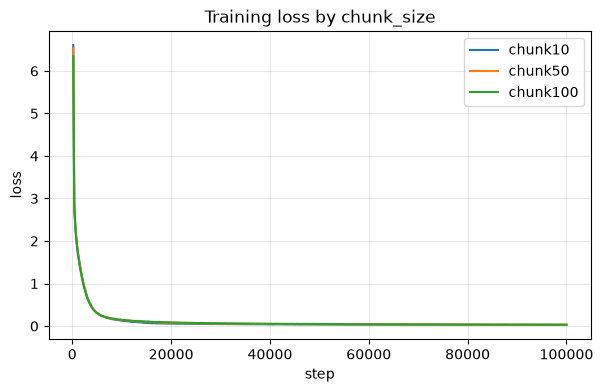

In [6]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 나머지 열이 조건별 loss (열 이름은 본인 파일에 맞게 수정)
import os
import matplotlib.pyplot as plt

CSV_PATH = "images/loss_hw3.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    for col in df.columns[1:]:
        plt.plot(df.iloc[:, 0], df[col], label=col)
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss by chunk_size")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

In [7]:
# [작성] 학습 종료 시점의 손실 (학습 로그 마지막 줄에서 확인)
# ACT는 l1_loss(행동 복원 손실)와 kld_loss(KL 항)를 따로 출력한다
final_loss = pd.DataFrame({
    "chunk_size": CHUNK_SIZES,
    "l1_loss":  [0.027857499197125435, 0.034644585102796555, 0.039566706866025925],
    "kld_loss": [3.430992364883423e-05, 5.7365745306015015e-05, 7.655099034309387e-05],
}).set_index("chunk_size")
final_loss

,l1_loss,kld_loss
chunk_size,,
10,0.027857,0.000034
50,0.034645,0.000057
100,0.039567,0.000077


## 3. 실로봇 평가 (조건별 10회, 총 30회)

### 3-1. 평가 프로토콜
1. 테이블에 물체 시작 위치 10곳을 테이프로 표시하고 1~10번을 매긴다. **세 정책 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준을 **평가 전에** 아래에 적고, 평가 도중 바꾸지 않는다.

`[작성]` 성공 기준
- 성공: 30초 내 좌측 큐브를 집어 우측 도착 구역에 내려놓고 그리퍼에서 놓음.
- 실패: 시간 내 완료하지 못함, 운반 중 낙하 또는 도착 구역 밖에 내려놓음.
- 에피소드 제한 시간(초): 30 (회차 사이 재배치 60초)

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`overhead`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어 3개를 붙여 넣는다. (`--policy.path`, `--dataset.num_episodes=10` 포함)

```powershell
# chunk_size = 10
lerobot-rollout --strategy.type=episodic --policy.path=alohateam1423/act_pick_cube_10 --robot.type=so101_follower --robot.port=COM6 --robot.id=follower1 --robot.calibration_dir="robot-env/cache/lerobot/calibration/robots/so101_follower" --robot.cameras='{"overhead":{"type":"opencv","index_or_path":2,"width":640,"height":480,"fps":25,"backend":700},"wrist":{"type":"opencv","index_or_path":1,"width":640,"height":480,"fps":25,"backend":700}}' --fps=30 --dataset.fps=30 --dataset.repo_id=alohateam1423/rollout_act_pick_cube_chunk10 --dataset.single_task="Grab the black cube" --dataset.num_episodes=10 --dataset.episode_time_s=30 --dataset.reset_time_s=60 --strategy.reset_to_initial_position=true --return_to_initial_position=false --dataset.push_to_hub=true --dataset.private=false --dataset.rgb_encoder.vcodec=h264 --device=cuda --play_sounds=false --display_data=false

# chunk_size = 50
lerobot-rollout --strategy.type=episodic --policy.path=alohateam1423/act_pick_cube_50 --robot.type=so101_follower --robot.port=COM6 --robot.id=follower1 --robot.calibration_dir="robot-env/cache/lerobot/calibration/robots/so101_follower" --robot.cameras='{"overhead":{"type":"opencv","index_or_path":2,"width":640,"height":480,"fps":25,"backend":700},"wrist":{"type":"opencv","index_or_path":1,"width":640,"height":480,"fps":25,"backend":700}}' --fps=30 --dataset.fps=30 --dataset.repo_id=alohateam1423/rollout_act_pick_cube_chunk50 --dataset.single_task="Grab the black cube" --dataset.num_episodes=10 --dataset.episode_time_s=30 --dataset.reset_time_s=60 --strategy.reset_to_initial_position=true --return_to_initial_position=false --dataset.push_to_hub=true --dataset.private=false --dataset.rgb_encoder.vcodec=h264 --device=cuda --play_sounds=false --display_data=false

# chunk_size = 100
lerobot-rollout --strategy.type=episodic --policy.path=alohateam1423/act_pick_cube --robot.type=so101_follower --robot.port=COM6 --robot.id=follower1 --robot.calibration_dir="robot-env/cache/lerobot/calibration/robots/so101_follower" --robot.cameras='{"overhead":{"type":"opencv","index_or_path":2,"width":640,"height":480,"fps":25,"backend":700},"wrist":{"type":"opencv","index_or_path":1,"width":640,"height":480,"fps":25,"backend":700}}' --fps=30 --dataset.fps=30 --dataset.repo_id=alohateam1423/rollout_act_pick_cube_chunk100 --dataset.single_task="Grab the black cube" --dataset.num_episodes=10 --dataset.episode_time_s=30 --dataset.reset_time_s=60 --strategy.reset_to_initial_position=true --return_to_initial_position=false --dataset.push_to_hub=true --dataset.private=false --dataset.rgb_encoder.vcodec=h264 --device=cuda --play_sounds=false --display_data=false
```

**실제 실행 방법 및 조건 차이:** Windows에서는 DLL 경로 설정과 USB 일련번호에 따른 COM 포트 탐색을 수행하는 실행 도우미를 사용했다. 위 명령은 도우미가 설치된 LeRobot `rollout(cfg)`에 전달한 설정과 대응하며, 실제 정책 경로는 해당 HF 모델을 내려받은 로컬 스냅샷 경로였다. `rollout-act.ps1 -Chunk 10/50/100 -Episodes 10 -Run`으로 시작하고, 중단된 실행은 `-ResumeRepo`와 추가 횟수를 지정해 같은 데이터셋에 이어 기록했다. 기본 정책은 앙상블을 끈 상태이며 추가 관절 목표 변화 제한은 사용하지 않았다.

카메라는 640×480, 25 FPS이며 제어/저장 목표는 학습 데이터와 같은 30 Hz였다. 실제 처리 속도는 목표보다 낮을 수 있다. 이번 평가의 카메라 배치와 배경은 학습 데이터 수집 당시와 달랐으며, 조건별 시작 위치·순서가 정확히 동일했는지는 별도 회차 기록으로 검증하지 못했다. 따라서 엄밀한 통제 실험으로서 한계가 있다.

**중단·재개:** chunk50은 1→7→10회, chunk100은 4→6→7→10회로 누적 저장했다. 기본 전역 키 리스너가 다른 창의 `n/r/q` 입력도 다음 회차/재녹화/종료로 처리함을 확인했다. 마지막 chunk100 3회와 앙상블은 이 단축키를 무시하고 Esc 중단만 유지했다. 폐기된 시도의 회차별 대응은 남아 있지 않아 세부 실패 원인을 소급해 만들지 않았다.


In [8]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CHUNK_SIZES:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"chunk{k:<4} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f"chunk {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

chunk10   에피소드 10개, 프레임 8521, fps 30  -> 통과


chunk50   에피소드 10개, 프레임 8845, fps 30  -> 통과


chunk100  에피소드 10개, 프레임 8885, fps 30  -> 통과
chunk 10 이름 규칙: 통과
chunk 50 이름 규칙: 통과
chunk 100 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. (예: "큐브 위치를 놓침", "청크가 바뀌는 순간 팔이 튐", "목표 근처에서 계속 떨림")
실험자는 모든 조건의 10회가 실패했고 부드러움은 모두 1점이었다고 보고했다. 위치 번호는 기록 순서를 나타내며, 실제 표식 위치와의 대응을 사후 검증하지 못했다. 회차별 원인은 확인되지 않아 구체적인 파지 실패 유형을 임의로 기입하지 않았다.


In [9]:
def blank(): 
    return [{"episode": i, "position": i + 1, "success": False, "smooth": 1, "note": "실험자 판정: 큐브 좌측→우측 이동 작업 미완료. 회차별 세부 원인은 별도 기록 없음."} for i in range(10)]

results = {
    10:  blank(),   # 실험자: 10회 모두 실패, 부드러움 1점
    50:  blank(),   # 실험자: 10회 모두 실패, 부드러움 1점
    100: blank(),   # 실험자: 10회 모두 실패, 부드러움 1점
}
# 예시: results[10][0] = {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "파지 직전 좌우로 떨리다 놓침"}

res_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("chunk_size")
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary

,success_rate,mean_smooth
chunk_size,,
10,0.0,1.0
50,0.0,1.0
100,0.0,1.0


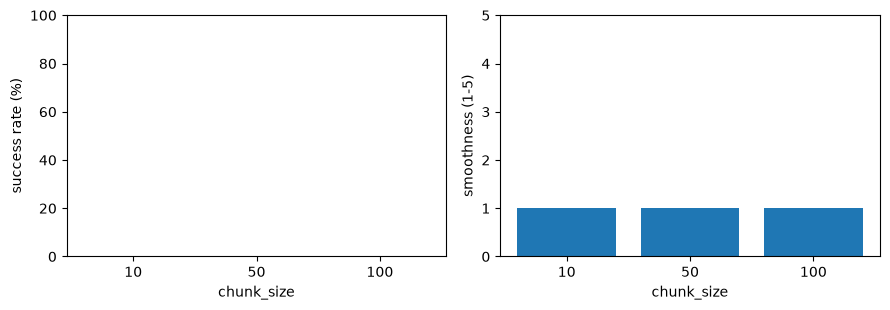

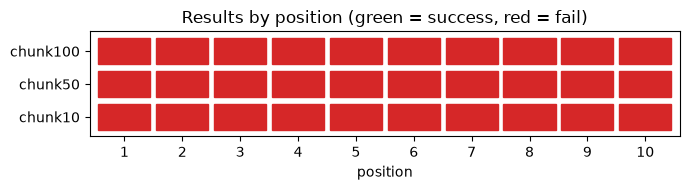

In [10]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
labels = [str(k) for k in summary.index]
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_xlabel("chunk_size"); axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_xlabel("chunk_size"); axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = chunk_size, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CHUNK_SIZES):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CHUNK_SIZES) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CHUNK_SIZES)))
ax.set_yticklabels([f"chunk{k}" for k in CHUNK_SIZES]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
조건별로 3회씩 추가로 시도하되, 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮긴다.** 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음)

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다.

`[작성]` 아래 `reactivity`를 채운다.
**실험자 확인 결과:** 청크 10·50·100에서 물체를 옮기는 테스트를 각각 3회 이상 수행했으며 모두 새 위치를 따라가지 못했다. 조건별 3회를 기록하면 각각 0/3이다. 이는 실험자의 관찰 판정이며, 이동 거리나 반응 시간을 센서로 계측한 결과는 아니다.


In [11]:
reactivity = {
    10:  [{"trial": i, "followed": False, "note": "실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함."} for i in range(3)],   # 실험자 확인 결과
    50:  [{"trial": i, "followed": False, "note": "실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함."} for i in range(3)],   # 실험자 확인 결과
    100: [{"trial": i, "followed": False, "note": "실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함."} for i in range(3)],   # 실험자 확인 결과
}
react_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in reactivity.items()], ignore_index=True)
print(react_df.groupby("chunk_size")["followed"].apply(lambda s: f"{int(s.fillna(False).sum())}/3" if s.notna().all() else "미확인 (조건별 3회 기록 없음)"))
react_df

chunk_size
10     0/3
50     0/3
100    0/3
Name: followed, dtype: object


,trial,followed,note,chunk_size
0,0,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,10
1,1,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,10
2,2,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,10
3,0,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,50
4,1,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,50
5,2,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,50
6,0,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,100
7,1,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,100
8,2,False,실험자 확인: 물체를 옮겨도 동작 변화가 없었고 새 위치를 따라가지 못함.,100


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
chunk_size에 따른 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: chunk10의 떨림, chunk100의 청크 경계 튐)

![chunk10](images/hw3_chunk10.gif)
![chunk50](images/hw3_chunk50.gif)
![chunk100](images/hw3_chunk100.gif)

위 GIF는 각 조건 첫 저장 에피소드의 외부 카메라 영상 0~12초를 같은 크기·재생 속도로 추출했다. 특정 성공 장면을 선별한 영상은 아니며, 전체 영상은 0절의 공개 HF 데이터셋에서 확인할 수 있다. 웹 뷰어에서의 재생 여부는 별도 확인하지 않았다.


## 4. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

세 기본 조건은 모두 성공률 0%, 부드러움 평균 1.0점으로 동일했다. 따라서 chunk50이 성공률에서 우세할 것이라는 예상은 이번 결과로 지지되지 않았다. 조건 간 우열이 드러나지 않는 낮은 성능에서는 청크 크기보다 공통 입력 환경과 데이터 분포의 영향을 먼저 점검해야 한다.


**4-2. 짧은 청크의 문제** — chunk_size=10에서 관찰된 동작의 특징(떨림, 머뭇거림, 경로 이탈 등)을 compounding error 개념으로 설명하라.

chunk10에서는 실험자가 거의 작동하지 않는다고 관찰했고, 10회 모두 실패 및 부드러움 1점으로 판정했다. 짧은 청크는 자주 재계획하지만, 잘못 예측한 행동이 다음 관측에 영향을 주면 분포 이탈과 오차 누적을 막지 못할 수 있다. 다만 이번 기록만으로 실제 떨림이나 머뭇거림의 원인을 compounding error로 확정할 수는 없다.


**4-3. 긴 청크의 대가** — chunk_size=100에서 청크가 바뀌는 순간 동작이 끊기거나 튀는 현상이 있었는가? 반응성 테스트 결과와 함께 설명하라.

chunk100도 성공률 0%, 부드러움 평균 1점으로 개선이 없었다. 명목 30 Hz에서 한 청크는 약 3.33초이므로, 기본 방식은 실행 중 물체 위치 변화 반영이 늦어질 수 있다. 물체를 옮기는 반응성 테스트에서도 세 조건 모두 0/3으로 새 위치를 따라가지 못했다. 다만 청크 경계의 튐이나 반응 시간을 별도로 계측하지 않았으므로, 실패를 긴 청크의 영향만으로 설명할 수는 없다.


**4-4. 오프라인 손실과 실제 성능** — 2-3의 `l1_loss`가 낮은 조건이 실로봇 성공률도 높았는가? 그렇지 않다면 이유는 무엇이라고 생각하는가?

최종 W&B L1 loss는 chunk10 약 0.02786, chunk50 약 0.03464, chunk100 약 0.03957이었다. L1이 가장 낮은 chunk10도 실제 성공률은 0%여서 낮은 학습 손실이 작업 성공으로 이어지지 않았다. 학습 때와 달라진 배경·카메라 구도와 시연 일관성 부족은 가능한 원인이지만, 원인별 통제 실험을 하지 않았으므로 가설로 남긴다.


**4-5. 내 태스크에 맞는 chunk_size** — 본인 태스크의 길이와 정밀도 요구 수준을 고려할 때 어떤 chunk_size가 적합한가? 실험하지 않은 값(예: 30)을 제안해도 된다.

좌측에서 큐브를 집어 우측에 놓는 작업은 파지 위치 보정과 안정적인 운반이 모두 필요하다. 이번에는 세 조건 모두 실패했으므로 최적 청크를 정할 근거가 없다. 다음 실험에서는 카메라 위치와 시작 자세를 고정해 데이터를 재수집한 뒤, chunk30 또는 50을 포함해 비교하고 실제 제어 주기도 함께 측정하겠다.



## 5. Temporal ensemble
chunk_size=100 정책을 그대로 두고 추론 방식만 바꿔, 매 스텝 추론하며 겹치는 예측을 가중 평균한다. 재학습은 필요 없다.

```powershell
.\robot-env\rollout-act.ps1 -Chunk 100 -Episodes 10 -Ensemble -Automatic -Run
# 기존 chunk100 모델에 --policy.n_action_steps=1 --policy.temporal_ensemble_coeff=0.01 적용
# 별도 repo: alohateam1423/rollout_act_pick_cube_chunk100_te (시각 자동 추가)
# 그 외 카메라·30초 제한·60초 리셋·제어/저장 목표 30 Hz는 기본 평가와 동일
```

> `lerobot-rollout`은 `--policy.path`로 불러온 설정 위에 `--policy.*` 값을 덮어쓴다. ACT는 `temporal_ensemble_coeff`를 설정하면 `n_action_steps=1`이어야 하며, 다른 값이면 시작할 때 오류를 낸다.

`[작성]` 3-1과 같은 위치·순서로 10회 평가하고 chunk100 결과와 성공률·부드러움·추론 지연을 비교한다. 3~5문장.

앙상블 적용 조건도 10회 모두 실패했고 부드러움 평균은 1.0점으로, 기본 chunk100과 차이가 없었다. 따라서 이번 환경에서는 겹치는 예측을 평균내는 것만으로 작업 성공이나 주관적 부드러움이 개선되지 않았다. 동일 저장 입력을 이용한 평가 후 비구동 측정에서 행동 출력 1회 평균 처리 시간은 기본 1.39 ms, 앙상블 15.99 ms였으며, 기본 방식은 청크 안의 행동을 재사용하는 반면 앙상블은 매번 새 추론을 수행한다. 학습 환경과 평가 환경의 차이를 먼저 줄인 뒤 앙상블 효과를 재평가할 필요가 있다.

**추론 지연 측정 방법:** RTX 5080 Laptop에서 같은 chunk100 가중치와 저장된 카메라 영상 1프레임·관절 상태를 두 조건에 입력했다. 조건별 100회 예열 후 정책을 초기화하고 500회 연속 호출했으며, 전처리→`select_action`→후처리를 CUDA 동기화로 측정했다. 로봇·카메라는 연결하지 않았다. 따라서 아래 값은 실로봇 평가 도중의 전체 제어 루프 지연이 아니라, 고정 입력에서의 정책 처리 시간이다. 기본 조건에서 새로운 청크 추론은 500회 중 5회, 앙상블은 500회 모두 발생한다.

| 조건 | 행동 출력 1회 평균(ms) | 중앙값(ms) | 95백분위(ms) | 새 예측 발생 호출 평균(ms) |
|---|---:|---:|---:|---:|
| chunk100 | 1.39 | 1.19 | 1.71 | 18.45 |
| chunk100 + temporal ensemble | 15.99 | 14.50 | 21.51 | 15.99 |

측정 원자료: [hw3_inference_latency.json](images/hw3_inference_latency.json). 기본 조건의 작은 평균·95백분위는 대부분의 호출이 큐에 저장된 행동을 꺼내기 때문이며, 새 신경망 추론 자체가 그만큼 빠르다는 의미는 아니다.


In [12]:
# 5. Temporal ensemble 결과 입력
TE_EVAL_DATASET = 'alohateam1423/rollout_act_pick_cube_chunk100_te_20261114_222714'
te_results = blank()   # 실험자: 10회 모두 실패, 부드러움 1점

te_info = load_json(TE_EVAL_DATASET, "meta/info.json", repo_type="dataset") if TE_EVAL_DATASET else None
if te_info:
    n_ep = te_info.get("total_episodes")
    print(f"temporal ensemble 에피소드 {n_ep}개 ->", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

te_df = pd.DataFrame(te_results)
if te_df["success"].notna().all():
    print(f"temporal ensemble 성공률: {te_df['success'].astype(float).mean()*100:.0f}%, 부드러움 평균: {te_df['smooth'].mean():.1f}")
    print(f"chunk100 성공률        : {summary.loc[100, 'success_rate']:.0f}%, 부드러움 평균: {summary.loc[100, 'mean_smooth']:.1f}")
else:
    print("te_results를 실제 결과로 채울 것")

temporal ensemble 에피소드 10개 -> 통과
temporal ensemble 성공률: 0%, 부드러움 평균: 1.0
chunk100 성공률        : 0%, 부드러움 평균: 1.0


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.
반응성 조건별 3회 결과는 실험자 확인으로 반영했고, 추론 지연은 별도의 비구동 벤치마크로 보완했다. 실패 회차의 note는 작업 미완료 판정을 적은 것이며, 구체적인 원인을 확인했다는 의미는 아니다. 체크리스트 출력과 별개로 이 한계를 함께 확인한다.


In [13]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        return fname in api.list_repo_files(rid, repo_type=rtype)
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in [*EVAL_DATASETS.values(), TE_EVAL_DATASET] if r),
}
for k in CHUNK_SIZES:
    check_items[f"chunk{k} 정책 업로드됨 (config.json, model.safetensors)"] = (
        file_ok(POLICY_REPOS[k], "config.json", "model") and file_ok(POLICY_REPOS[k], "model.safetensors", "model"))
    check_items[f"chunk{k} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"chunk{k} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"chunk{k} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["통제 변수 일치 (1-3)"] = all(cfg_df[c].nunique(dropna=False) == 1 for c in ["dataset", "steps", "batch_size", "seed"])
check_items["반응성 테스트 9회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)
check_items["temporal ensemble 평가 데이터셋 에피소드 10개"] = bool(te_info) and te_info.get("total_episodes") == 10
check_items["temporal ensemble 회차별 결과 10개 입력"] = all(r["success"] is not None for r in te_results)
check_items["temporal ensemble 실패 회차에 원인 기재"] = all(r["note"].strip() for r in te_results if r["success"] is False)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] chunk10 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk10 평가 데이터셋 에피소드 10개
[통과] chunk10 회차별 결과 10개 입력
[통과] chunk10 실패 회차에 원인 기재
[통과] chunk50 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk50 평가 데이터셋 에피소드 10개
[통과] chunk50 회차별 결과 10개 입력
[통과] chunk50 실패 회차에 원인 기재
[통과] chunk100 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk100 평가 데이터셋 에피소드 10개
[통과] chunk100 회차별 결과 10개 입력
[통과] chunk100 실패 회차에 원인 기재
[통과] 통제 변수 일치 (1-3)
[통과] 반응성 테스트 9회 입력
[통과] temporal ensemble 평가 데이터셋 에피소드 10개
[통과] temporal ensemble 회차별 결과 10개 입력
[통과] temporal ensemble 실패 회차에 원인 기재

모두 통과
